# Yield Curve History (Heatmap + Spread)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Shows the whole term structure through time as a heatmap (maturity × date, color = yield), with the 10Y–2Y spread in a panel below. Decades of rate cycles, curve flattening and inversions fit in one figure.

## When to use

- Show how the entire yield curve evolved over years or decades
- Relate policy-rate cycles to curve shape and inversions
- Use as long-horizon macro context for fixed-income or allocation reports

## Avoid when

- Readers need exact yields on a given day (use a table or a single-date curve)
- Using a rainbow colormap (it creates false bands); use one hue, light to dark

## Alternatives

- Small-multiple yield curves by year
- Lines for 2Y and 10Y yields over time

## Design tips

- Put short maturities at the bottom so 'up' means longer maturity
- Share the time axis between the heatmap and the spread panel
- Color the spread panel by sign: blue for a normal curve, orange for an inverted one

## Example

Monthly curves for 2000–2025 generated with a Nelson–Siegel model whose level and slope loosely follow past US rate cycles (simulated, not actual data).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(17)
dates = pd.date_range("2000-01-31", "2025-12-31", freq="ME")
t = dates.year + (dates.month - 1) / 12
anchors_short = {2000: 6.0, 2001.9: 1.8, 2004: 1.0, 2006.5: 5.2, 2008.9: 0.2, 2015.9: 0.2,
                 2019.3: 2.4, 2020.3: 0.1, 2022.0: 0.2, 2023.0: 4.4, 2023.6: 5.4, 2024.6: 5.3, 2025.9: 4.0}
anchors_long = {2000: 6.3, 2003: 4.3, 2007: 4.9, 2012.5: 2.0, 2016: 2.2, 2018.8: 3.1, 2020.5: 1.0,
                2022.0: 1.9, 2023.0: 3.8, 2023.8: 4.8, 2025.9: 4.6}
short = np.interp(t, list(anchors_short), list(anchors_short.values())) + rng.normal(0, 0.06, len(t))
level = np.interp(t, list(anchors_long), list(anchors_long.values())) + rng.normal(0, 0.12, len(t))
curve = rng.normal(0, 0.3, len(t)).cumsum() * 0.05

maturities = ["3M", "6M", "1Y", "2Y", "3Y", "5Y", "7Y", "10Y", "20Y", "30Y"]
tau = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])
lam = 1.8
f1 = (1 - np.exp(-tau / lam)) / (tau / lam)
f2 = f1 - np.exp(-tau / lam)
beta1 = short - level                                 # Nelson-Siegel slope factor
yields = level[:, None] + beta1[:, None] * f1 + curve[:, None] * f2
yields = pd.DataFrame(np.clip(yields, 0.05, None), index=dates, columns=maturities).round(2)
yields["spread_10y_2y"] = yields["10Y"] - yields["2Y"]
yields.iloc[::60]

,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y,spread_10y_2y
2000-01-31,6.08,6.09,6.11,6.13,6.15,6.18,6.19,6.20,6.22,6.22,0.07
2005-01-31,2.85,2.97,3.17,3.48,3.71,3.99,4.15,4.28,4.44,4.50,0.80
2010-01-31,0.33,0.53,0.89,1.45,1.85,2.35,2.65,2.89,3.20,3.30,1.44
2015-01-31,0.29,0.43,0.66,1.02,1.27,1.59,1.76,1.91,2.09,2.15,0.89
2020-01-31,0.93,1.00,1.11,1.28,1.39,1.51,1.58,1.63,1.69,1.71,0.35
2025-01-31,4.96,4.97,4.98,4.98,4.96,4.93,4.89,4.86,4.81,4.79,-0.12


### Plot

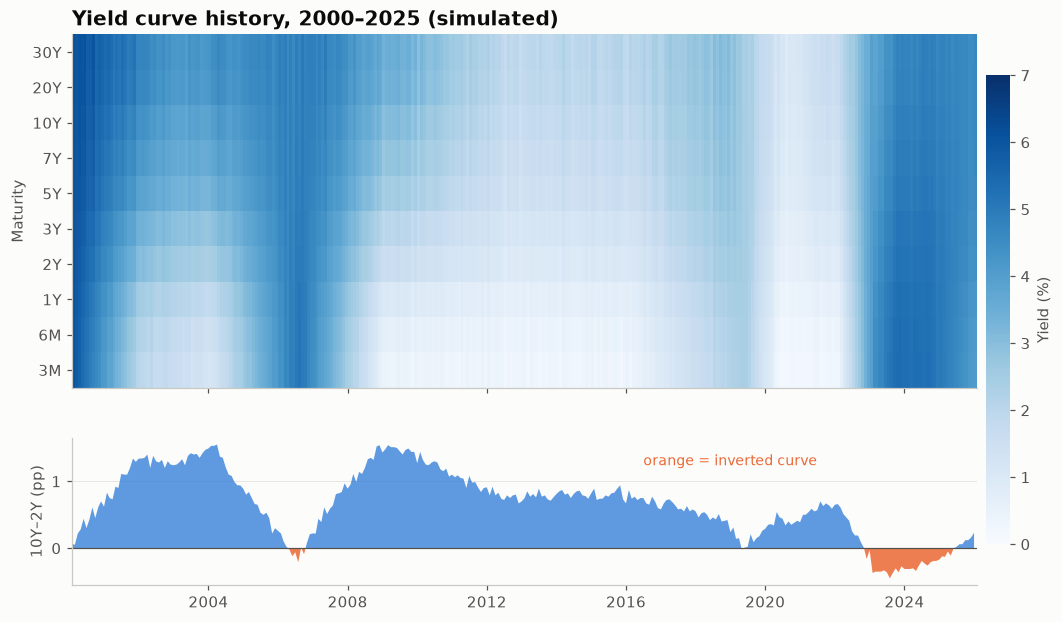

In [3]:
fig, (ax, axs) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                              gridspec_kw={"height_ratios": [2.4, 1]})
z = yields[maturities].to_numpy().T
x_edges = yields.index.append(pd.DatetimeIndex([yields.index[-1] + pd.offsets.MonthEnd(1)]))
mesh = ax.pcolormesh(x_edges, np.arange(len(maturities) + 1), z, cmap=SEQ_CMAP, vmin=0, vmax=7)
ax.set_yticks(np.arange(len(maturities)) + 0.5, maturities)
ax.set_ylabel("Maturity")
ax.grid(False)
ax.set_title("Yield curve history, 2000–2025 (simulated)")

s = yields["spread_10y_2y"]
axs.fill_between(s.index, s, 0, where=s >= 0, color=PALETTE[0], alpha=0.75, linewidth=0, interpolate=True)
axs.fill_between(s.index, s, 0, where=s < 0, color=PALETTE[1], alpha=0.85, linewidth=0, interpolate=True)
axs.axhline(0, color="#52514e", linewidth=0.8)
axs.set_ylabel("10Y–2Y (pp)")
axs.text(pd.Timestamp("2016-06-30"), s.max() * 0.8, "orange = inverted curve", color=PALETTE[1], fontsize=9)
axs.grid(axis="x", visible=False)
cb = fig.colorbar(mesh, ax=[ax, axs], fraction=0.025, pad=0.01)
cb.set_label("Yield (%)")
cb.outline.set_visible(False)
plt.show()

## How to read it

Light vertical stripes are low-rate eras and dark stripes high-rate eras. When the bottom rows (short maturities) are darker than the top rows, the curve is inverted, and the lower panel turns orange.

---
Standalone script: [`yield_curve_history.py`](yield_curve_history.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)